<center><h1>Yi_Jiahe_HW3</h1></center>
<br>
<br>

Name: Jiahe Yi
<br>
Github Username: beaverjuly
<br>
USC ID: 5689143499

## 1. Time Series Classification Part 1: Feature Creation/Extraction

In [1]:
# All imports for the entire notebook live in this single cell.
import os
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

warnings.filterwarnings("ignore")

# reproducibility
RANDOM_STATE = 552
np.random.seed(RANDOM_STATE)

# plotting defaults
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["savefig.bbox"] = "tight"
plt.rcParams["axes.titleweight"] = "bold"

# pandas display
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 60)

import sklearn, scipy
print("numpy       :", np.__version__)
print("pandas      :", pd.__version__)
print("matplotlib  :", plt.matplotlib.__version__)
print("seaborn     :", sns.__version__)
print("scipy       :", scipy.__version__)
print("sklearn     :", sklearn.__version__)

numpy       : 2.4.4
pandas      : 3.0.2
matplotlib  : 3.10.8
seaborn     : 0.13.2
scipy       : 1.17.1
sklearn     : 1.8.0


In [2]:
# Locate the data using a relative path with forward slashes only.
DATA_DIR_CANDIDATES = ["data/AReM", "../data/AReM"]


def resolve_dir(candidates):
    """Return the first existing relative directory from `candidates`."""
    for path in candidates:
        if os.path.isdir(path):
            return path
    raise FileNotFoundError("Could not find the AReM folder. Looked in: "
                            + ", ".join(candidates))


DATA_DIR = resolve_dir(DATA_DIR_CANDIDATES)
print("Data directory:", DATA_DIR)

ACTIVITIES = ["bending1", "bending2", "cycling", "lying", "sitting", "standing", "walking"]
SERIES = ["avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]


def dataset_number(filename):
    """'dataset12.csv' gives 12, so files sort numerically rather than as text."""
    return int(re.findall(r"\d+", filename)[0])


inventory = []
for act in ACTIVITIES:
    for fname in sorted(os.listdir(DATA_DIR + "/" + act), key=dataset_number):
        if fname.endswith(".csv"):
            inventory.append((act, dataset_number(fname), DATA_DIR + "/" + act + "/" + fname))

counts = pd.Series([a for a, _, _ in inventory]).value_counts().reindex(ACTIVITIES)
print("\nInstances per activity:")
print(counts.to_string())
print(f"\nTotal instances: {len(inventory)}")

Data directory: data/AReM

Instances per activity:
bending1     7
bending2     6
cycling     15
lying       15
sitting     15
standing    15
walking     15

Total instances: 88


In [3]:
# Step 1. What does a naive read do? Flag every file that does not come
# back as a clean 480 x 7 numeric table.
naive_problems = []
for act, k, path in inventory:
    try:
        d = pd.read_csv(path, comment="#", header=None)
        if d.shape != (480, 7):
            naive_problems.append((act + "/dataset" + str(k) + ".csv",
                                   "parsed as shape " + str(d.shape)))
    except Exception as err:
        naive_problems.append((act + "/dataset" + str(k) + ".csv",
                               type(err).__name__ + ": " + str(err).split(".")[0]))

print("Files a naive pd.read_csv(..., comment='#') does NOT read cleanly:\n")
for f, msg in naive_problems:
    print(f"  {f:24s} {msg}")

Files a naive pd.read_csv(..., comment='#') does NOT read cleanly:

  bending2/dataset4.csv    parsed as shape (480, 1)
  cycling/dataset9.csv     ParserError: Error tokenizing data
  cycling/dataset14.csv    ParserError: Error tokenizing data
  sitting/dataset8.csv     parsed as shape (479, 7)


In [4]:
# Step 2. A robust loader that handles every irregularity found above.
#   * skips the '#' metadata lines at the top of each file
#   * accepts commas or whitespace as the delimiter
#   * drops empty tokens produced by a trailing delimiter
#   * insists on exactly 7 numeric fields per data line (fails loudly otherwise)
def load_instance(path):
    rows = []
    with open(path, encoding="utf-8") as fh:
        for line_no, line in enumerate(fh, start=1):
            line = line.strip()
            if not line or line.startswith("#"):
                continue
            tokens = [t for t in re.split(r"[,\s]+", line) if t != ""]
            if len(tokens) != 7:
                raise ValueError(f"{path}, line {line_no}: expected 7 fields, got {len(tokens)}")
            rows.append([float(t) for t in tokens])
    return pd.DataFrame(rows, columns=["time"] + SERIES)


instances = []
for act, k, path in inventory:
    instances.append({"activity": act, "dataset": k, "data": load_instance(path)})

n_rows = pd.Series([len(r["data"]) for r in instances])
all_values = pd.concat([r["data"][SERIES] for r in instances])

print(f"Loaded {len(instances)} instances")
print(f"Rows per instance: {n_rows.value_counts().sort_index().to_dict()}")
print(f"Missing values   : {int(all_values.isna().sum().sum())}")
print(f"Negative values  : {int((all_values < 0).sum().sum())}")

Loaded 88 instances
Rows per instance: {479: 1, 480: 87}
Missing values   : 0
Negative values  : 0


In [5]:
# The one short file: which reading is missing, and does it matter?
short = [r for r in instances if len(r["data"]) != 480][0]
t = short["data"]["time"].values
missing_t = sorted(set(np.arange(0, 480 * 250, 250)) - set(t))
print(f"{short['activity']}/dataset{short['dataset']}.csv has {len(t)} rows; "
      f"missing timestamp(s) (ms): {missing_t}")

# Compare summary statistics with and without linearly interpolating the gap.
d = short["data"].set_index("time")
filled = d.reindex(np.arange(0, 480 * 250, 250)).interpolate()
funcs = [np.min, np.max, np.mean, np.median, lambda s: np.std(s, ddof=1),
         lambda s: np.percentile(s, 25), lambda s: np.percentile(s, 75)]
max_change = max(abs(f(filled[s].values) - f(d[s].values)) for s in SERIES for f in funcs)
print(f"Largest change in any of its 42 summary statistics if the gap is "
      f"interpolated: {max_change:.4f}")

sitting/dataset8.csv has 479 rows; missing timestamp(s) (ms): [np.int64(13500)]
Largest change in any of its 42 summary statistics if the gap is interpolated: 0.0081


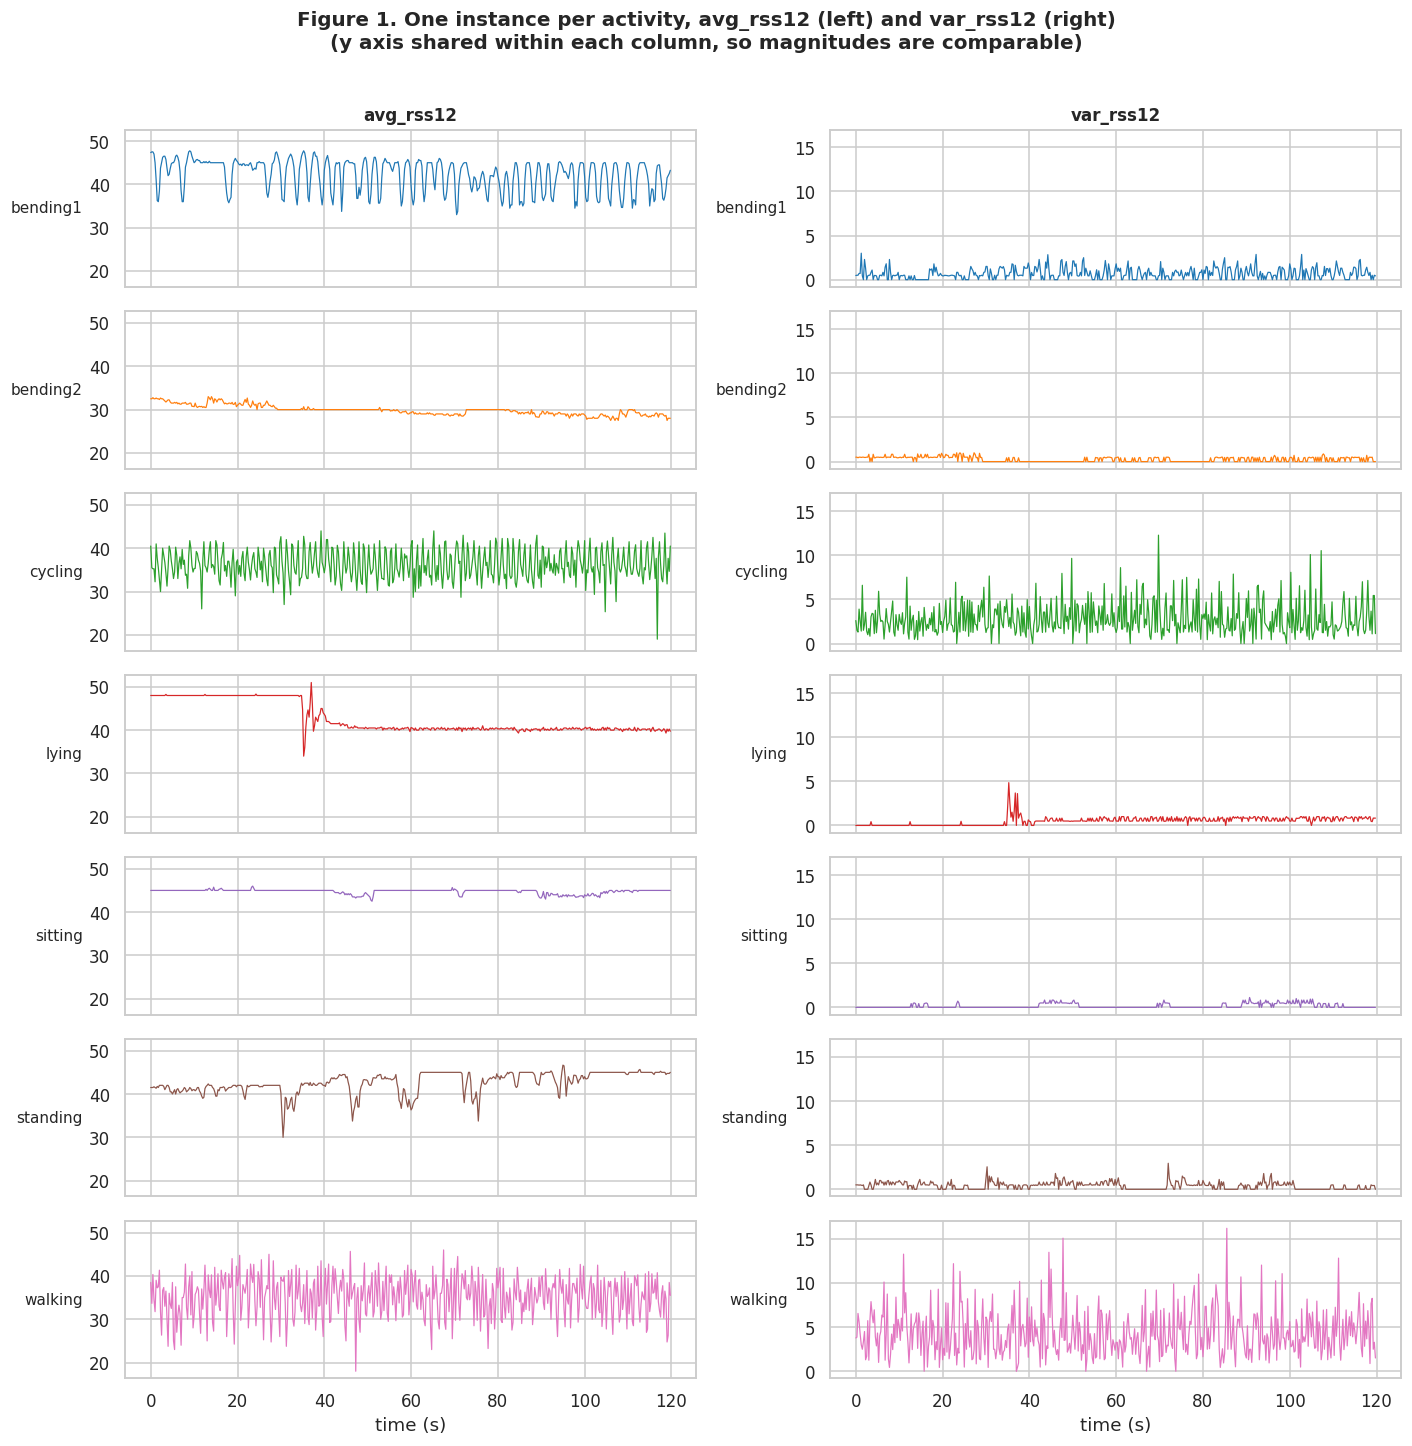

          mean of avg_rss12  sd of avg_rss12  mean of var_rss12
activity                                                       
bending1              42.18             3.67               0.70
bending2              29.88             1.15               0.26
cycling               36.23             3.53               2.83
lying                 42.71             3.54               0.52
sitting               44.75             0.52               0.15
standing              42.65             2.40               0.40
walking               35.19             4.75               4.32


In [6]:
# Figure 1 shows one representative training instance per activity.
# (dataset 4 is a training instance in every folder, see part (b).)
fig, axes = plt.subplots(len(ACTIVITIES), 2, figsize=(13, 13), sharex=True, sharey="col")
palette = dict(zip(ACTIVITIES, sns.color_palette("tab10", len(ACTIVITIES))))

for row, act in enumerate(ACTIVITIES):
    rec = [r for r in instances if r["activity"] == act and r["dataset"] == 4][0]
    tsec = rec["data"]["time"] / 1000
    for col, series in enumerate(["avg_rss12", "var_rss12"]):
        ax = axes[row, col]
        ax.plot(tsec, rec["data"][series], lw=0.8, color=palette[act])
        ax.set_ylabel(act, fontsize=10, rotation=0, ha="right", va="center")
        if row == 0:
            ax.set_title(series, fontsize=11)
axes[-1, 0].set_xlabel("time (s)")
axes[-1, 1].set_xlabel("time (s)")
fig.suptitle("Figure 1. One instance per activity, avg_rss12 (left) and var_rss12 (right)\n"
             "(y axis shared within each column, so magnitudes are comparable)",
             fontsize=13, fontweight="bold", y=1.01)
fig.tight_layout()
plt.show()

# The numbers behind the description of Figure 1.
fig1_stats = pd.DataFrame(
    [(act, r["data"]["avg_rss12"].mean(), r["data"]["avg_rss12"].std(),
      r["data"]["var_rss12"].mean())
     for act in ACTIVITIES
     for r in instances if r["activity"] == act and r["dataset"] == 4],
    columns=["activity", "mean of avg_rss12", "sd of avg_rss12", "mean of var_rss12"],
).set_index("activity")
print(fig1_stats.round(2).to_string())

1(a). The data set contains 88 instances in 7 activity folders, with 7 and 6 instances for the two types of bending and 15 for each of the other five activities. Each instance has 6 time series of 480 consecutive values, one every 250 ms for 120 seconds.

Four files needed cleaning, and I handled all of them in code without editing the raw files. The file bending2/dataset4.csv is space delimited instead of comma delimited, so my loader accepts commas or whitespace as delimiters. The files cycling/dataset9.csv and cycling/dataset14.csv have a trailing comma on their last line, which creates an empty eighth field, so the loader drops empty tokens. The file sitting/dataset8.csv has 479 rows because the reading at t = 13500 ms is missing.

I did not impute the missing reading in sitting/dataset8.csv. The check above shows that linearly interpolating it would change none of that instance's 42 summary statistics by more than 0.0081.

Figure 1 suggests why the activities should be separable, at least in these example instances. Walking and cycling have much larger var_rss12 (means of 4.32 and 2.83) than the five static postures (0.15 to 0.70). The static postures differ in their avg_rss12 level instead, for example about 30 for this bending2 instance versus about 45 for sitting, which is also the steadiest signal with a standard deviation of 0.52.

### (b) Test and Train Data

In [7]:
# (b) The test set is datasets 1 and 2 of bending1 and bending2, and datasets 1, 2 and 3 elsewhere.
def is_test(activity, k):
    if activity in ("bending1", "bending2"):
        return k in (1, 2)
    return k in (1, 2, 3)


for r in instances:
    r["split"] = "test" if is_test(r["activity"], r["dataset"]) else "train"

split_tab = (pd.DataFrame([(r["activity"], r["split"]) for r in instances],
                          columns=["activity", "split"])
             .value_counts().unstack(fill_value=0).reindex(ACTIVITIES))
split_tab = split_tab[["train", "test"]]
split_tab["total"] = split_tab.sum(axis=1)
split_tab.loc["TOTAL"] = split_tab.sum()

test_files = {act: [r["dataset"] for r in instances
                    if r["activity"] == act and r["split"] == "test"] for act in ACTIVITIES}
split_tab["test datasets"] = [str(test_files.get(a, "")) if a in test_files else ""
                              for a in split_tab.index]

print(split_tab.to_string())

split     train  test  total test datasets
activity                                  
bending1      5     2      7        [1, 2]
bending2      4     2      6        [1, 2]
cycling      12     3     15     [1, 2, 3]
lying        12     3     15     [1, 2, 3]
sitting      12     3     15     [1, 2, 3]
standing     12     3     15     [1, 2, 3]
walking      12     3     15     [1, 2, 3]
TOTAL        69    19     88              


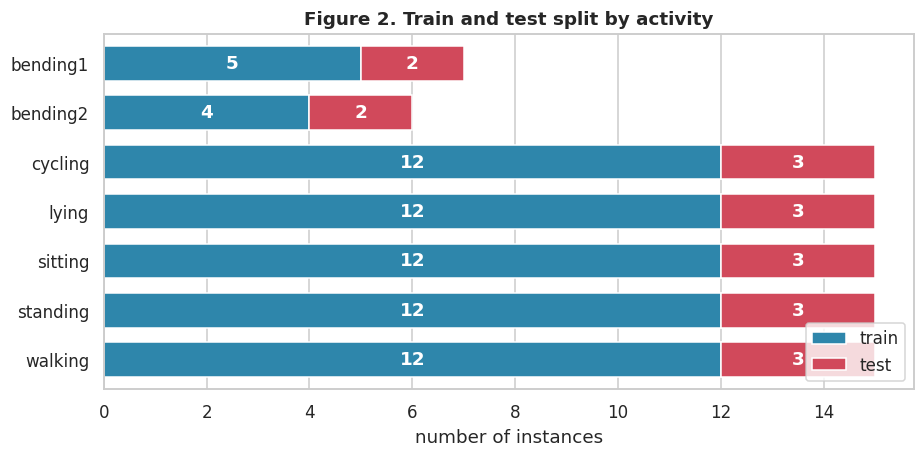

In [8]:
fig, ax = plt.subplots(figsize=(9.5, 4.2))
plot_tab = split_tab.drop("TOTAL")[["train", "test"]]
plot_tab.plot(kind="barh", stacked=True, color=["#2E86AB", "#D1495B"], ax=ax, width=0.7)
for i, (tr, te) in enumerate(plot_tab.values):
    ax.text(tr / 2, i, str(tr), va="center", ha="center", color="white", fontweight="bold")
    ax.text(tr + te / 2, i, str(te), va="center", ha="center", color="white", fontweight="bold")
ax.set_xlabel("number of instances")
ax.set_ylabel("")
ax.invert_yaxis()
ax.set_title("Figure 2. Train and test split by activity")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
plt.show()

1(b). Following the instructions, I put datasets 1 and 2 of bending1 and bending2, and datasets 1, 2 and 3 of every other activity, in the test set. All remaining instances form the training set. This gives 19 test instances (2 + 2 + 5 × 3) and 69 training instances (5 + 4 + 5 × 12).

The two bending classes have only 5 and 4 training instances, compared with 12 for every other activity. This limits the number of stratified folds I can use for cross validation on the training set in 1(c)iv, and it is relevant to the class imbalance questions in Homework 4.

### (c) Feature Extraction

1(c)i. Time domain features are computed directly from the sequence of values, without first transforming the series into the frequency domain as Fourier or wavelet features do. They are cheap to compute and easy to interpret, which is why they are a standard first step in activity recognition from sensor data. The features most commonly used fall into the following groups.

* Location. Mean, median and mode.
* Spread. Standard deviation or variance, range (maximum minus minimum, also called peak to peak amplitude), interquartile range, mean or median absolute deviation, and the coefficient of variation.
* Order statistics. Minimum, maximum, quartiles and other percentiles.
* Distribution shape. Skewness and kurtosis.
* Magnitude and energy. Root mean square, signal energy (the sum of squared values) and the crest factor (peak value divided by root mean square).
* Temporal dynamics. Zero crossing or mean crossing rate, number of peaks, autocorrelation at a chosen lag, slope of a fitted linear trend, and mean absolute first difference.
* Complexity. Sample entropy and approximate entropy.

The first five groups treat a series as an unordered collection of values. The last two depend on the order of the observations, so they capture how the signal changes over time. This assignment uses seven features from the first three groups. My list is based on Figo et al. (2010), Bulling, Blanke and Schiele (2014), and Christ et al. (2018), cited in the References.

In [9]:
# (c) ii. Seven time domain features x six series = 42 features per instance.
# I use the features directly, without normalising. The standard deviations in
# part iii must be on the original scale, and the measures used in part iv
# (ANOVA F, correlation) are scale invariant anyway.
FEATURE_FUNCS = [
    ("min",       lambda s: s.min()),
    ("max",       lambda s: s.max()),
    ("mean",      lambda s: s.mean()),
    ("median",    lambda s: s.median()),
    ("std",       lambda s: s.std(ddof=1)),        # sample standard deviation
    ("1st_quart", lambda s: s.quantile(0.25)),
    ("3rd_quart", lambda s: s.quantile(0.75)),
]
FEATURE_TYPES = [name for name, _ in FEATURE_FUNCS]

rows = []
for r in instances:
    row = {}
    for i, series in enumerate(SERIES, start=1):
        for name, func in FEATURE_FUNCS:
            row[f"{name}{i}"] = func(r["data"][series])
    rows.append(row)

features = pd.DataFrame(rows, index=pd.RangeIndex(1, len(rows) + 1, name="Instance"))
meta = pd.DataFrame({"activity": [r["activity"] for r in instances],
                     "dataset": [r["dataset"] for r in instances],
                     "split": [r["split"] for r in instances]}, index=features.index)

print(f"Feature matrix: {features.shape[0]} instances x {features.shape[1]} features")
print("Column order (per series i = 1..6):", ", ".join(f"{n}i" for n in FEATURE_TYPES))

Feature matrix: 88 instances x 42 features
Column order (per series i = 1..6): mini, maxi, meani, mediani, stdi, 1st_quarti, 3rd_quarti


In [10]:
# The full extracted data set, in the layout requested by the assignment.
with pd.option_context("display.max_rows", 100, "display.max_columns", 50,
                       "display.precision", 3):
    display(pd.concat([meta, features], axis=1))

,activity,dataset,split,min1,max1,mean1,median1,std1,1st_quart1,3rd_quart1,min2,max2,mean2,median2,std2,1st_quart2,3rd_quart2,min3,max3,mean3,median3,std3,1st_quart3,3rd_quart3,min4,max4,mean4,median4,std4,1st_quart4,3rd_quart4,min5,max5,mean5,median5,std5,1st_quart5,3rd_quart5,min6,max6,mean6,median6,std6,1st_quart6,3rd_quart6
Instance,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1,bending1,1,test,37.25,45.00,40.625,40.500,1.477,39.250,42.000,0.0,1.30,0.359,0.430,0.323,0.000,0.500,4.00,29.50,19.041,19.250,4.463,16.000,23.250,0.0,7.23,0.833,0.500,0.966,0.000,1.120,27.25,38.25,34.311,35.000,2.188,33.000,36.000,0.00,1.92,0.571,0.430,0.583,0.000,1.300
2,bending1,2,test,38.00,45.67,42.813,42.500,1.436,42.000,43.670,0.0,1.22,0.372,0.470,0.289,0.000,0.500,2.00,29.50,20.097,21.000,3.894,19.000,22.250,0.0,5.76,0.876,0.500,1.047,0.000,1.145,27.67,38.50,33.025,33.000,1.995,32.000,34.500,0.00,3.11,0.571,0.430,0.601,0.000,1.300
3,bending1,3,train,35.00,47.40,43.955,44.330,1.559,43.000,45.000,0.0,1.70,0.426,0.470,0.339,0.000,0.500,6.50,29.75,22.122,23.000,3.031,19.750,24.000,0.0,4.44,0.497,0.430,0.551,0.000,0.830,29.00,38.50,35.588,36.000,2.000,35.362,36.500,0.00,1.79,0.493,0.430,0.514,0.000,0.940
4,bending1,4,train,33.00,47.75,42.180,43.500,3.671,39.150,45.000,0.0,3.00,0.696,0.500,0.631,0.000,1.120,8.50,30.00,22.184,23.000,3.810,20.500,24.372,0.0,5.15,0.990,0.830,0.954,0.430,1.300,20.00,38.67,33.494,35.000,3.849,30.457,36.330,0.00,2.18,0.614,0.500,0.524,0.000,1.000
5,bending1,5,train,33.00,45.75,41.678,41.750,2.243,41.330,42.750,0.0,2.83,0.536,0.500,0.405,0.430,0.710,3.00,28.25,19.007,19.125,4.087,16.500,22.062,0.0,6.42,0.842,0.500,0.929,0.430,1.120,23.67,37.50,29.857,30.000,2.411,28.457,31.250,0.00,1.79,0.383,0.430,0.389,0.000,0.500
6,bending1,6,train,37.00,48.00,43.455,43.250,1.386,42.500,45.000,0.0,1.58,0.378,0.470,0.316,0.000,0.500,5.75,27.00,15.793,15.000,3.848,13.000,18.270,0.0,10.03,0.849,0.500,0.996,0.430,1.120,8.00,33.50,23.035,23.500,2.489,22.250,24.000,0.00,5.26,0.680,0.500,0.623,0.430,0.870
7,bending1,7,train,36.25,48.00,43.969,44.500,1.618,43.310,44.670,0.0,1.50,0.413,0.470,0.263,0.430,0.500,1.50,26.33,15.868,16.250,3.742,14.250,18.000,0.0,5.17,0.666,0.470,0.789,0.000,0.940,11.33,30.75,22.104,21.670,3.318,20.500,23.750,0.00,2.96,0.555,0.490,0.488,0.000,0.830
8,bending2,1,test,12.75,51.00,24.563,24.250,3.738,23.188,26.500,0.0,6.87,0.591,0.430,0.837,0.000,0.710,0.00,25.33,19.121,20.250,4.300,18.000,22.000,0.0,6.76,0.737,0.470,0.927,0.000,0.870,10.67,30.00,23.493,23.750,3.694,20.500,27.000,0.00,4.97,0.700,0.500,0.694,0.430,0.870
9,bending2,2,test,0.00,42.75,27.465,28.000,3.584,25.500,30.000,0.0,7.76,0.450,0.430,0.767,0.000,0.500,7.50,35.00,20.843,20.750,3.826,18.000,22.500,0.0,5.76,0.780,0.500,0.904,0.000,0.940,0.00,33.00,17.618,18.000,5.054,15.000,20.750,0.00,6.76,1.122,0.830,1.012,0.470,1.300


1(c)ii. The new data set has 88 rows, one per instance, and 42 features. For each of the six series there are seven columns named min, max, mean, median, std, 1st_quart and 3rd_quart followed by the series number, from min1 up to 3rd_quart6, which matches the layout in the assignment. I numbered the instances 1 to 88 in folder order from bending1 to walking, and kept the activity, the dataset number and the train or test assignment next to the features for Homework 4.

I used the sample standard deviation, with $n-1$ in the denominator, and the pandas default linear interpolation for the quartiles. I used the features directly without normalising them, because the standard deviations in 1(c)iii should be in the original units and the measures I use in 1(c)iv do not depend on scale.

#### iii. Standard Deviation

For each of the 42 features I estimated its standard deviation across the 88 instances and built a 90% bootstrap confidence interval for that standard deviation using the percentile method. I drew B = 5000 bootstrap samples, each made of 88 instances drawn with replacement from the original 88. In each bootstrap sample I recomputed the standard deviation of every feature, and the 5th and 95th percentiles of the 5000 values give the 90% interval.

I resampled whole instances so that each instance keeps its 42 features together. I used all 88 instances because this is a descriptive estimate of each feature's variability rather than a modelling decision.

In [11]:
# (c) iii. Percentile bootstrap, vectorised over all 42 features at once.
B = 5000
rng = np.random.default_rng(RANDOM_STATE)
X = features.values                                    # (88, 42)

boot_rows = rng.integers(0, len(X), size=(B, len(X)))  # (5000, 88) row indices
boot_std = X[boot_rows].std(axis=1, ddof=1)            # (5000, 42)

ci_lo, ci_hi = np.percentile(boot_std, [5, 95], axis=0)
sd_table = pd.DataFrame({
    "Std (estimate)": features.std(ddof=1).values,
    "90% CI lower": ci_lo,
    "90% CI upper": ci_hi,
}, index=features.columns)
sd_table["CI width / estimate"] = (
    (sd_table["90% CI upper"] - sd_table["90% CI lower"]) / sd_table["Std (estimate)"])

with pd.option_context("display.max_rows", 50, "display.precision", 4):
    display(sd_table)

,Std (estimate),90% CI lower,90% CI upper,CI width / estimate
min1,9.5700,8.2747,10.7675,0.2605
max1,4.3944,3.3513,5.2701,0.4366
mean1,5.3357,4.7137,5.8976,0.2219
median1,5.4401,4.7896,6.0093,0.2242
std1,1.7722,1.5766,1.9460,0.2084
1st_quart1,6.1536,5.5747,6.6658,0.1773
3rd_quart1,5.1389,4.3472,5.8512,0.2927
min2,0.0000,0.0000,0.0000,NaN
max2,5.0627,4.6177,5.3975,0.1540
mean2,1.5742,1.3927,1.7046,0.1981


In [12]:
# Independent cross check against the SciPy built in percentile bootstrap.
def scipy_bootstrap_ci(x, seed=RANDOM_STATE):
    stat = lambda a, axis: np.std(a, axis=axis, ddof=1)
    kw = dict(confidence_level=0.90, n_resamples=5000, method="percentile")
    try:                                   # SciPy >= 1.15
        res = stats.bootstrap((x,), stat, rng=np.random.default_rng(seed), **kw)
    except TypeError:                      # older SciPy
        res = stats.bootstrap((x,), stat, random_state=np.random.default_rng(seed), **kw)
    return res.confidence_interval.low, res.confidence_interval.high


print(f"{'feature':10s} {'my 90% CI':>22s} {'scipy 90% CI':>22s}")
max_gap = 0.0
for col in ["min1", "mean1", "std2", "max6", "3rd_quart4"]:
    lo, hi = scipy_bootstrap_ci(features[col].values)
    ours_lo, ours_hi = sd_table.loc[col, "90% CI lower"], sd_table.loc[col, "90% CI upper"]
    max_gap = max(max_gap, abs(lo - ours_lo), abs(hi - ours_hi))
    print(f"{col:10s} [{ours_lo:8.4f}, {ours_hi:8.4f}]   [{lo:8.4f}, {hi:8.4f}]")

if max_gap < 1e-9:
    print("\nIdentical: given the same seed, SciPy draws exactly the same bootstrap samples.")
else:
    print(f"\nLargest difference {max_gap:.4f}: SciPy drew different random samples in this "
          "version, so agreement is to within Monte Carlo error.")

feature                 my 90% CI           scipy 90% CI
min1       [  8.2747,  10.7675]   [  8.2747,  10.7675]
mean1      [  4.7137,   5.8976]   [  4.7137,   5.8976]
std2       [  0.8026,   0.9415]   [  0.8026,   0.9415]
max6       [  2.2571,   2.7687]   [  2.2571,   2.7687]
3rd_quart4 [  1.4331,   1.6265]   [  1.4331,   1.6265]

Identical: given the same seed, SciPy draws exactly the same bootstrap samples.


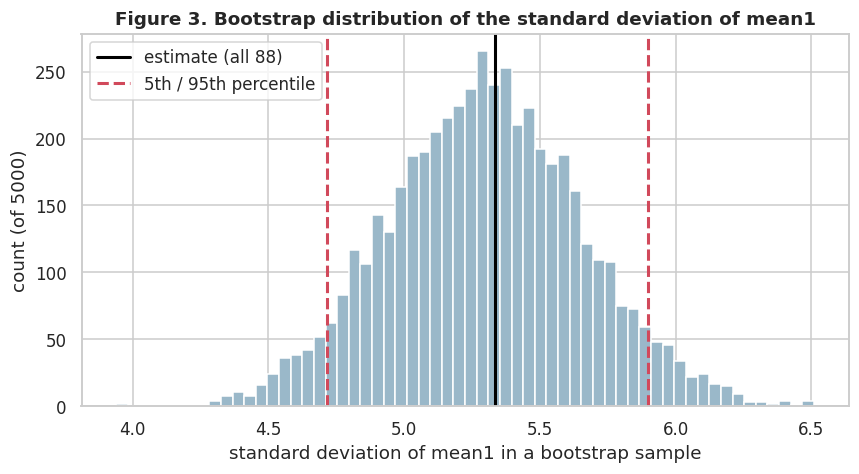

In [13]:
# Figure 3 shows what a bootstrap distribution looks like for one feature.
col = "mean1"
j = features.columns.get_loc(col)
fig, ax = plt.subplots(figsize=(9, 4.4))
ax.hist(boot_std[:, j], bins=60, color="#9AB8C9", edgecolor="white")
ax.axvline(sd_table.loc[col, "Std (estimate)"], color="black", lw=2, label="estimate (all 88)")
ax.axvline(sd_table.loc[col, "90% CI lower"], color="#D1495B", lw=2, ls="--",
           label="5th / 95th percentile")
ax.axvline(sd_table.loc[col, "90% CI upper"], color="#D1495B", lw=2, ls="--")
ax.set_xlabel(f"standard deviation of {col} in a bootstrap sample")
ax.set_ylabel("count (of 5000)")
ax.set_title(f"Figure 3. Bootstrap distribution of the standard deviation of {col}")
ax.legend()
plt.show()

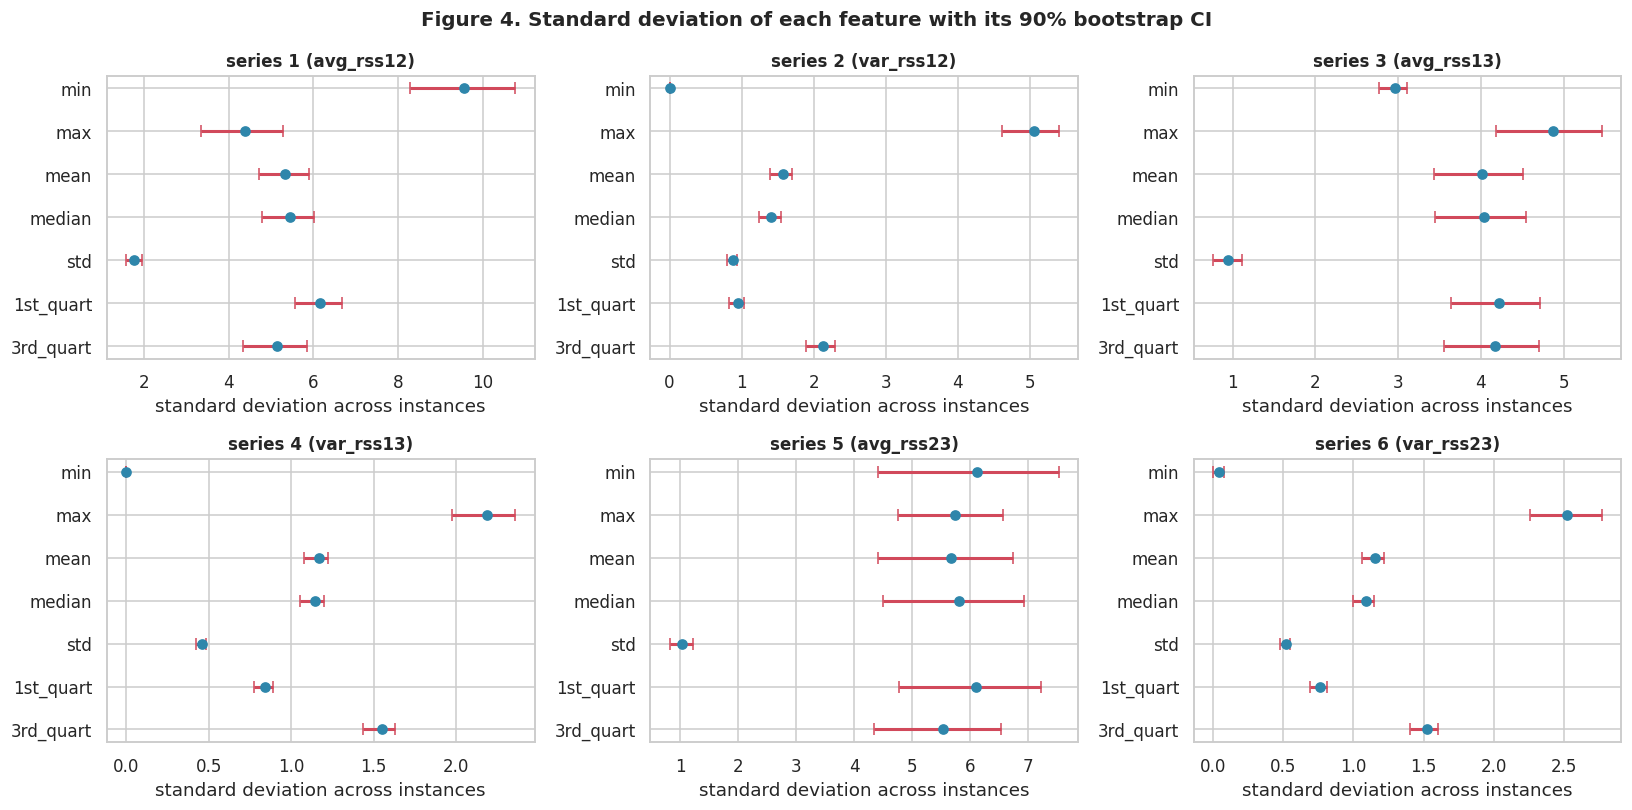

In [14]:
# Figure 4 shows the estimate and 90% CI for every feature, one panel per series
# (features from different series are on very different scales).
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
for i, ax in enumerate(axes.ravel(), start=1):
    sub = sd_table.loc[[f"{n}{i}" for n in FEATURE_TYPES]]
    ypos = np.arange(len(sub))[::-1]
    est = sub["Std (estimate)"].values
    ax.errorbar(est, ypos,
                xerr=[est - sub["90% CI lower"].values, sub["90% CI upper"].values - est],
                fmt="o", color="#2E86AB", ecolor="#D1495B", elinewidth=2, capsize=4)
    ax.set_yticks(ypos)
    ax.set_yticklabels(FEATURE_TYPES)
    ax.set_title(f"series {i} ({SERIES[i - 1]})", fontsize=11)
    ax.set_xlabel("standard deviation across instances")
fig.suptitle("Figure 4. Standard deviation of each feature with its 90% bootstrap CI",
             fontsize=13, fontweight="bold")
fig.tight_layout()
plt.show()

1(c)iii. The table above gives, for all 42 features, the estimated standard deviation across the 88 instances and its 90% percentile bootstrap confidence interval with B = 5000. My vectorised implementation gives exactly the same intervals as scipy.stats.bootstrap when both use the same random seed. For example, the standard deviation of min1 is 9.570 with interval [8.275, 10.768], that of max1 is 4.394 with interval [3.351, 5.270], and that of mean1 is 5.336 with interval [4.714, 5.898].

Two features are constant. The minima min2 and min4 of the variance series var_rss12 and var_rss13 equal 0 in all 88 instances, so their standard deviation is exactly 0 and the interval is [0, 0]. The variance series reach zero whenever the signal stays perfectly still within a 250 ms window, which happens in every recording.

The feature min6 is almost constant, and its interval shows a limitation of the bootstrap. It is 0 in 87 of the 88 instances, so its standard deviation of 0.046 depends on a single observation. A bootstrap sample leaves out any given instance with probability $(1 - 1/88)^{88} \approx 0.37$, so more than 5% of the resamples have a standard deviation of exactly 0 and the lower bound of the interval is 0. The interval [0, 0.079] should therefore not be read as a precise estimate.

Because the features are on different scales, I compared the interval widths relative to the estimates. Leaving out the degenerate minima, min5 is estimated least precisely, with an interval width of about 51% of its estimate, followed by max1 at 44%, while min3 is estimated most precisely at 12%.

#### iv. Select Features

I judged importance with the goal of Homework 4 in mind, which is to distinguish the activities, and I used only the training set so that the test set does not influence the choice. I combined four pieces of evidence, computed in the cells below.

In [15]:
# Evidence 1. Degenerate features carry no information at all.
print("Share of instances in which each minimum equals 0:")
for i in range(1, 7):
    share = (features[f"min{i}"] == 0).mean()
    print(f"  min{i} ({SERIES[i - 1]:9s}): {share:6.1%}")

Share of instances in which each minimum equals 0:
  min1 (avg_rss12):   2.3%
  min2 (var_rss12): 100.0%
  min3 (avg_rss13):  36.4%
  min4 (var_rss13): 100.0%
  min5 (avg_rss23):  27.3%
  min6 (var_rss23):  98.9%


In [16]:
# Evidence 2. Class separation, measured by the one way ANOVA F statistic of each feature
# across the 7 activities (training set only). Large F = class means differ
# a lot relative to the spread within each class.
train = meta["split"] == "train"
anova_F = {}
for c in features.columns:
    groups = [features.loc[train & (meta["activity"] == a), c].values for a in ACTIVITIES]
    anova_F[c] = stats.f_oneway(*groups).statistic       # NaN for constant features

F_grid = pd.DataFrame({t: [anova_F[f"{t}{i}"] for i in range(1, 7)] for t in FEATURE_TYPES},
                      index=[f"{i}: {s}" for i, s in enumerate(SERIES, start=1)])

print("ANOVA F by feature type and series (training set):")
print(F_grid.round(1).to_string())
print("\nMedian F across the six series (NaN = constant feature, skipped):")
print(F_grid.median().sort_values(ascending=False).round(1).to_string())

ANOVA F by feature type and series (training set):
               min   max   mean  median    std  1st_quart  3rd_quart
1: avg_rss12  11.0   1.5   15.9    17.5    9.1       21.4        8.5
2: var_rss12   NaN  47.7  900.2   477.0  360.9      265.5      807.0
3: avg_rss13  22.7  31.7   26.4    19.4   15.2       21.2       28.1
4: var_rss13   NaN  29.3  651.8   800.8  128.6      244.8      561.9
5: avg_rss23  24.1  37.0   33.4    28.6    7.8       25.5       32.2
6: var_rss23   0.8  33.0  581.5   563.1  133.4      346.3      664.8

Median F across the six series (NaN = constant feature, skipped):
mean         307.4
3rd_quart    297.1
median       252.8
1st_quart    135.2
std           71.9
max           32.3
min           16.8


In [17]:
# Evidence 3. Redundancy, measured by the correlation between feature types, averaged
# over the six series (training set). min is omitted because it is constant
# for three of the six series, so its correlation is undefined there.
types_wo_min = [t for t in FEATURE_TYPES if t != "min"]
corr_sum = np.zeros((len(types_wo_min), len(types_wo_min)))
for i in range(1, 7):
    corr_sum += features.loc[train, [f"{t}{i}" for t in types_wo_min]].corr().values
redundancy = pd.DataFrame(corr_sum / 6, index=types_wo_min, columns=types_wo_min)
print("Mean correlation between feature types (training set):")
print(redundancy.round(3).to_string())

Mean correlation between feature types (training set):
             max   mean  median    std  1st_quart  3rd_quart
max        1.000  0.786   0.753  0.628      0.712      0.820
mean       0.786  1.000   0.991  0.383      0.980      0.981
median     0.753  0.991   1.000  0.363      0.977      0.965
std        0.628  0.383   0.363  1.000      0.277      0.497
1st_quart  0.712  0.980   0.977  0.277      1.000      0.934
3rd_quart  0.820  0.981   0.965  0.497      0.934      1.000


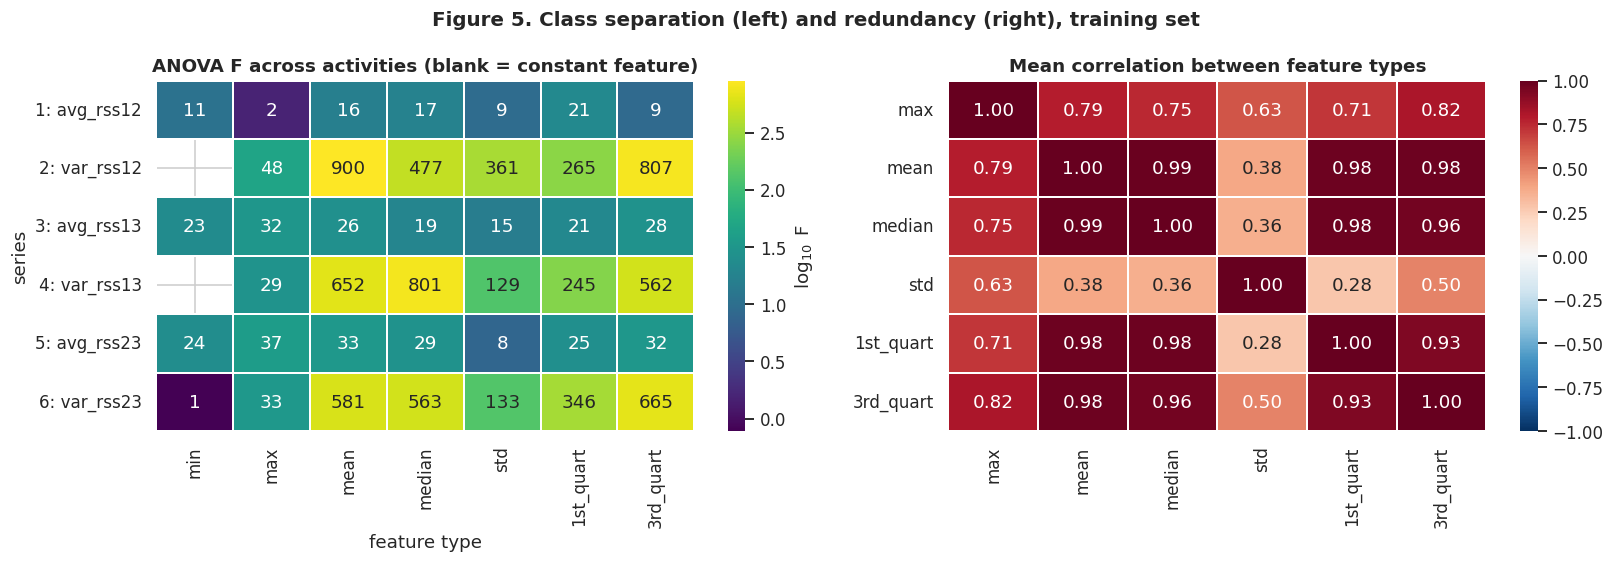

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))

sns.heatmap(np.log10(F_grid), annot=F_grid, fmt=".0f", cmap="viridis",
            linewidths=1, linecolor="white", ax=axes[0],
            cbar_kws={"label": r"$\log_{10}$ F"})
axes[0].set_title("ANOVA F across activities (blank = constant feature)")
axes[0].set_xlabel("feature type"); axes[0].set_ylabel("series")

sns.heatmap(redundancy, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            linewidths=1, linecolor="white", ax=axes[1])
axes[1].set_title("Mean correlation between feature types")

fig.suptitle("Figure 5. Class separation (left) and redundancy (right), training set",
             fontsize=13, fontweight="bold")
fig.tight_layout()
plt.show()

In [19]:
# Evidence 4. A direct check of how well candidate triples of feature
# types (3 types x 6 series = 18 features) classify the 7 activities.
# Repeated stratified 4 fold CV on the training set only. Four folds is
# the most the smallest class allows (bending2 has 4 training instances).
y_train = meta.loc[train, "activity"].values
cv = RepeatedStratifiedKFold(n_splits=4, n_repeats=10, random_state=0)
models = {
    "KNN (k=3)": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=3)),
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)),
}
candidates = [("min", "mean", "max"), ("mean", "std", "max"), ("mean", "std", "3rd_quart"),
              ("1st_quart", "3rd_quart", "std"), ("min", "mean", "std"),
              ("min", "max", "std"), ("mean", "median", "1st_quart")]

cv_rows = []
for trip in candidates:
    cols = [f"{t}{i}" for t in trip for i in range(1, 7)]
    row = {"triple": ", ".join(trip)}
    for name, model in models.items():
        s = cross_val_score(model, features.loc[train, cols].values, y_train, cv=cv)
        row[name + " mean"] = s.mean()
        row[name + " sd"] = s.std()
    cv_rows.append(row)

cv_tab = pd.DataFrame(cv_rows).set_index("triple")
cv_tab = cv_tab.sort_values("KNN (k=3) mean", ascending=False)
print("CV accuracy, 4 folds x 10 repeats (mean and SD across folds)")
print(cv_tab.round(3).to_string())

CV accuracy, 4 folds x 10 repeats (mean and SD across folds)
                           KNN (k=3) mean  KNN (k=3) sd  Logistic regression mean  Logistic regression sd
triple                                                                                                   
mean, std, max                      0.906         0.052                     0.892                   0.062
mean, std, 3rd_quart                0.900         0.066                     0.896                   0.060
1st_quart, 3rd_quart, std           0.899         0.051                     0.897                   0.061
min, mean, std                      0.867         0.066                     0.878                   0.072
min, max, std                       0.865         0.063                     0.845                   0.090
min, mean, max                      0.852         0.052                     0.873                   0.076
mean, median, 1st_quart             0.836         0.069                     0.857          

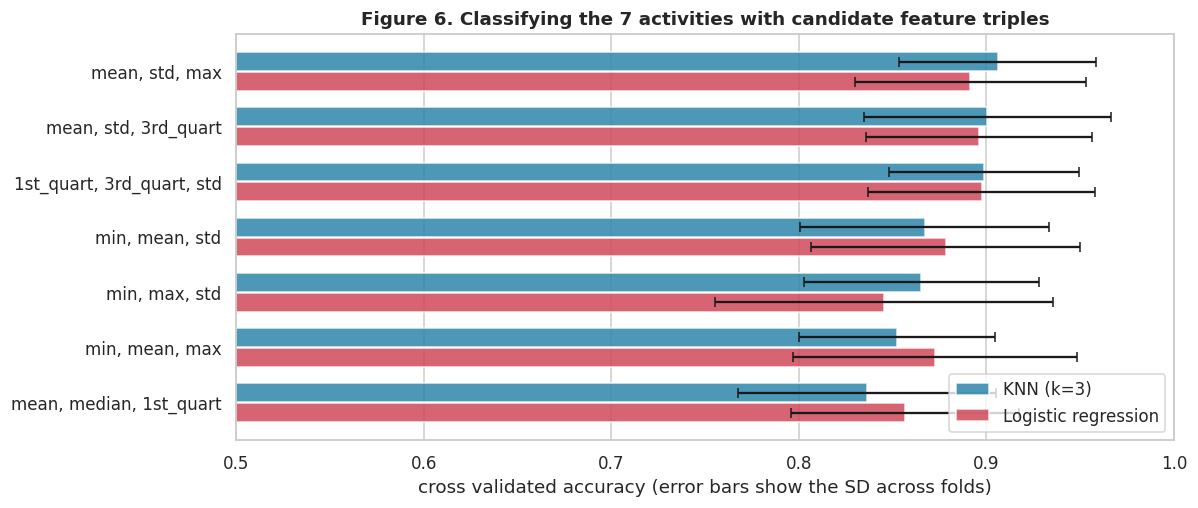

In [20]:
fig, ax = plt.subplots(figsize=(11, 4.8))
ypos = np.arange(len(cv_tab))
for off, (name, colr) in zip([-0.18, 0.18], [("KNN (k=3)", "#2E86AB"),
                                             ("Logistic regression", "#D1495B")]):
    ax.barh(ypos + off, cv_tab[name + " mean"], height=0.34, xerr=cv_tab[name + " sd"],
            color=colr, alpha=0.85, capsize=3, label=name)
ax.set_yticks(ypos)
ax.set_yticklabels(cv_tab.index)
ax.invert_yaxis()
ax.set_xlim(0.5, 1.0)
ax.set_xlabel("cross validated accuracy (error bars show the SD across folds)")
ax.set_title("Figure 6. Classifying the 7 activities with candidate feature triples")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
plt.show()

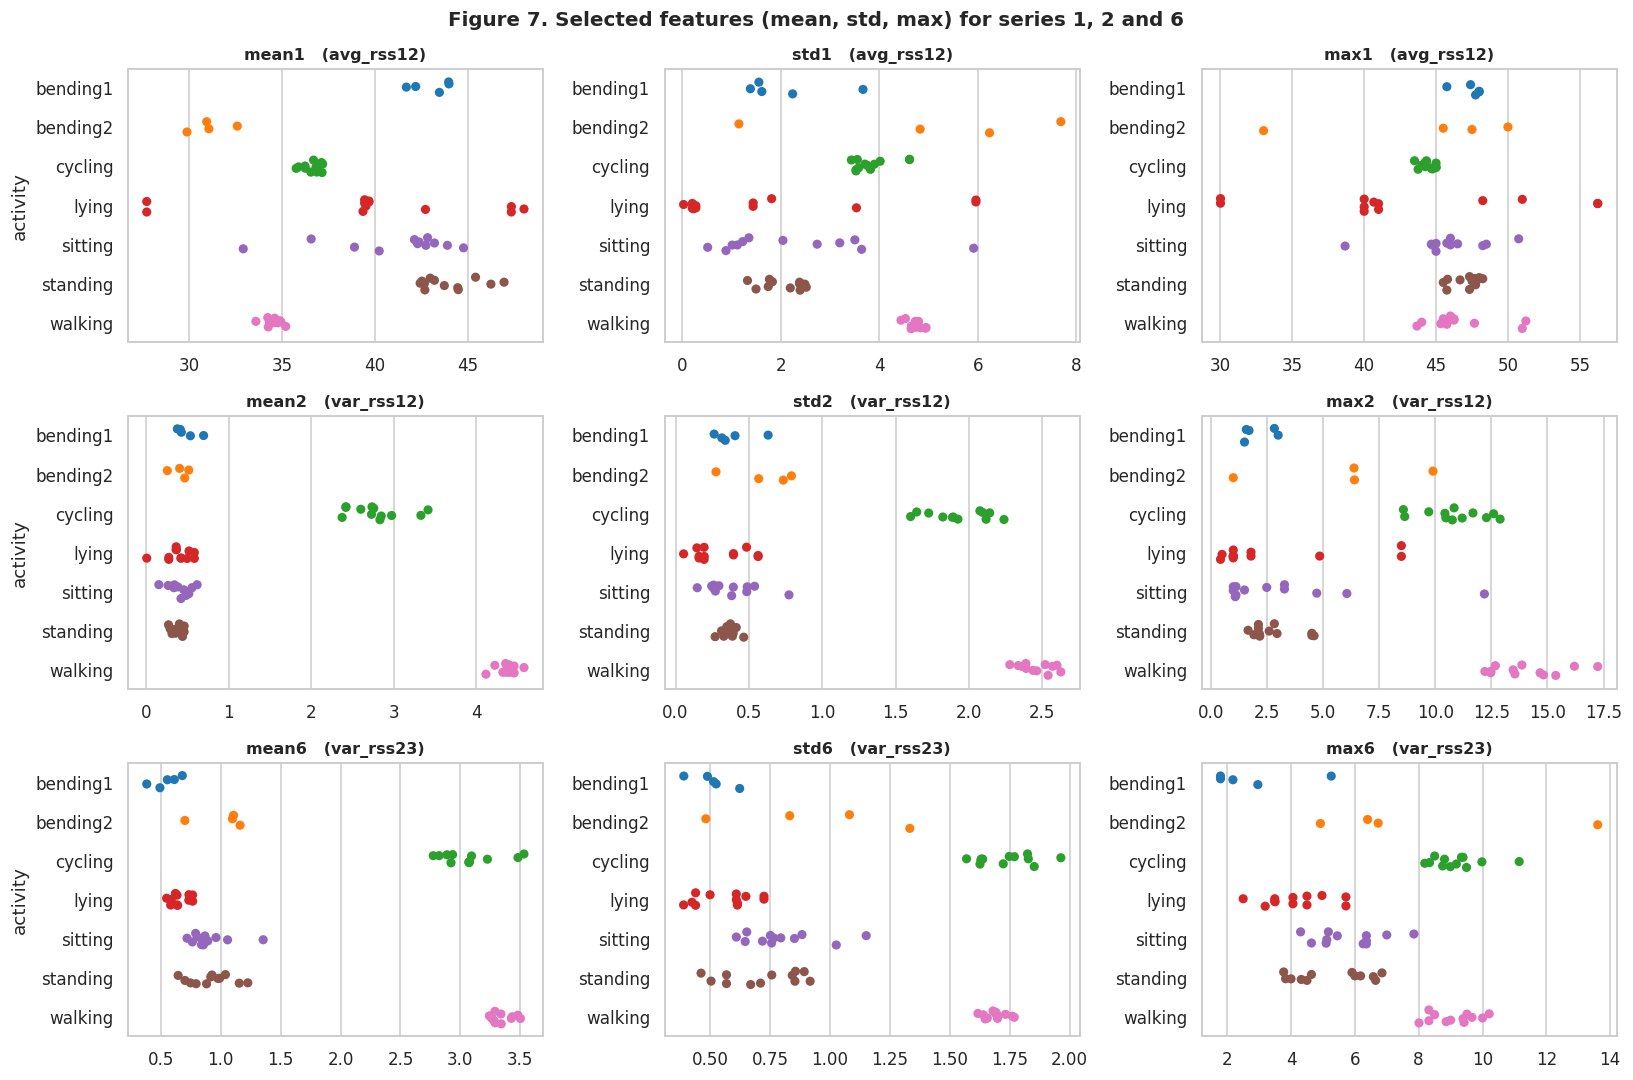

In [21]:
# Figure 7 shows the selected features for series 1, 2 and 6 (the series that
# Homework 4 uses), training set, split by activity.
SELECTED = ["mean", "std", "max"]
fig, axes = plt.subplots(3, 3, figsize=(15, 10))
plot_df = pd.concat([meta.loc[train], features.loc[train]], axis=1)
for r_i, s in enumerate([1, 2, 6]):
    for c_i, t in enumerate(SELECTED):
        ax = axes[r_i, c_i]
        sns.stripplot(data=plot_df, y="activity", x=f"{t}{s}", hue="activity",
                      order=ACTIVITIES, palette=palette, size=6, jitter=0.18,
                      legend=False, ax=ax)
        ax.set_title(f"{t}{s}   ({SERIES[s - 1]})", fontsize=10.5)
        ax.set_ylabel("" if c_i else "activity")
        ax.set_xlabel("")
fig.suptitle("Figure 7. Selected features (mean, std, max) for series 1, 2 and 6",
             fontsize=13, fontweight="bold")
fig.tight_layout()
plt.show()

1(c)iv. The evidence above supports keeping the mean and the maximum but replacing the minimum with the standard deviation, for four reasons.

First, the minimum is degenerate for half of the series. The minima min2 and min4 are 0 in 100% of the instances and min6 in 98.9%, so the minimum carries almost no information for the three variance series, including series 2 and 6, which Homework 4 plots. In the cross validation check, every triple containing the minimum also scores below the three best triples with both classifiers.

Second, the location measures are almost interchangeable, so I kept only one of them. The mean, the median and the two quartiles are nearly collinear, with average correlations with the mean of 0.99 for the median and 0.98 for each quartile, and the triple built only from them (mean, median, 1st quart) scores lowest of all with KNN. Of the four, the mean has the largest median ANOVA F statistic (307).

Third, the standard deviation adds a different kind of information. It measures spread rather than level, and it is the feature type least correlated with the mean (0.38).

Fourth, the maximum adds information about extremes. It is much less redundant with the mean (0.79) than the third quartile is (0.98), even though the two perform similarly in the cross validation.

Together the selected triple covers location, spread and extremes with little overlap. In the cross validation check in Figure 6, (mean, std, max) reaches about 0.91 accuracy with KNN and 0.89 with logistic regression, compared with about 0.85 and 0.87 for (min, mean, max).

With only 69 training instances, the standard deviation of the accuracy across folds is roughly 0.05 to 0.09, so (mean, std, max), (mean, std, 3rd quart) and (1st quart, 3rd quart, std) perform similarly within the observed cross validation variability. The cross validation supports my choice but does not single it out on its own, and the first two reasons above are the decisive ones. Among these three similarly performing triples, the selected one is the only one without a nearly duplicate pair. Its most correlated pair, the mean and the maximum, has a correlation of 0.79, whereas (mean, std, 3rd quart) pairs the mean with the third quartile (0.98) and (1st quart, 3rd quart, std) pairs the two quartiles (0.93).

## 2. ISLR 3.7.4

In this problem a linear regression and a cubic regression, $Y = \beta_0 + \beta_1 X + \beta_2 X^2 + \beta_3 X^3 + \varepsilon$, are fit to n = 100 observations with a single predictor. The linear model is nested inside the cubic model, since setting $\beta_2 = \beta_3 = 0$ gives the linear model. This settles the two training RSS questions, while the two test RSS questions depend on the bias variance tradeoff.

To illustrate the answers I ran a small simulation with n = 100 and three true relationships (linear, mildly nonlinear and strongly nonlinear). I used 2000 replications for each, with an independent test set of 100 points in every replication.

In [22]:
# Simulation supporting ISLR 3.7.4 (a) to (d).
def simulate(f, reps=2000, n=100, noise_sd=1.0, seed=0):
    r = np.random.default_rng(seed)
    out = []
    for _ in range(reps):
        x, xt = r.uniform(-2, 2, n), r.uniform(-2, 2, n)
        y = f(x) + r.normal(0, noise_sd, n)
        yt = f(xt) + r.normal(0, noise_sd, n)
        rss = {}
        for name, deg in [("linear", 1), ("cubic", 3)]:
            X = np.vander(x, deg + 1)
            Xt = np.vander(xt, deg + 1)
            beta = np.linalg.lstsq(X, y, rcond=None)[0]
            rss[name + "_train"] = ((y - X @ beta) ** 2).sum()
            rss[name + "_test"] = ((yt - Xt @ beta) ** 2).sum()
        out.append(rss)
    return pd.DataFrame(out)


truths = {
    "linear: 1 + 2x": lambda x: 1 + 2 * x,
    "mildly nonlinear: 1 + 2x + 0.05x^3": lambda x: 1 + 2 * x + 0.05 * x ** 3,
    "strongly nonlinear: 1 + 2x + 0.5x^3": lambda x: 1 + 2 * x + 0.5 * x ** 3,
}
sims = {name: simulate(f, seed=s) for s, (name, f) in enumerate(truths.items())}

summary_rows = []
for name, d in sims.items():
    summary_rows.append({
        "true relationship": name,
        "train RSS linear": d["linear_train"].mean(),
        "train RSS cubic": d["cubic_train"].mean(),
        "cubic train RSS lower": (d["cubic_train"] < d["linear_train"]).mean(),
        "test RSS linear": d["linear_test"].mean(),
        "test RSS cubic": d["cubic_test"].mean(),
        "linear test RSS lower": (d["linear_test"] < d["cubic_test"]).mean(),
    })
sim_tab = pd.DataFrame(summary_rows).set_index("true relationship")
print("Averages over 2000 replications (n = 100 train, 100 test, noise sd = 1):")
print(sim_tab.round(3).to_string())

Averages over 2000 replications (n = 100 train, 100 test, noise sd = 1):
                                     train RSS linear  train RSS cubic  cubic train RSS lower  test RSS linear  test RSS cubic  linear test RSS lower
true relationship                                                                                                                                    
linear: 1 + 2x                                 98.444           96.472                    1.0          101.799         103.911                  0.739
mildly nonlinear: 1 + 2x + 0.05x^3             98.119           95.817                    1.0          101.778         103.413                  0.640
strongly nonlinear: 1 + 2x + 0.5x^3           133.869           95.926                    1.0          139.197         104.254                  0.004


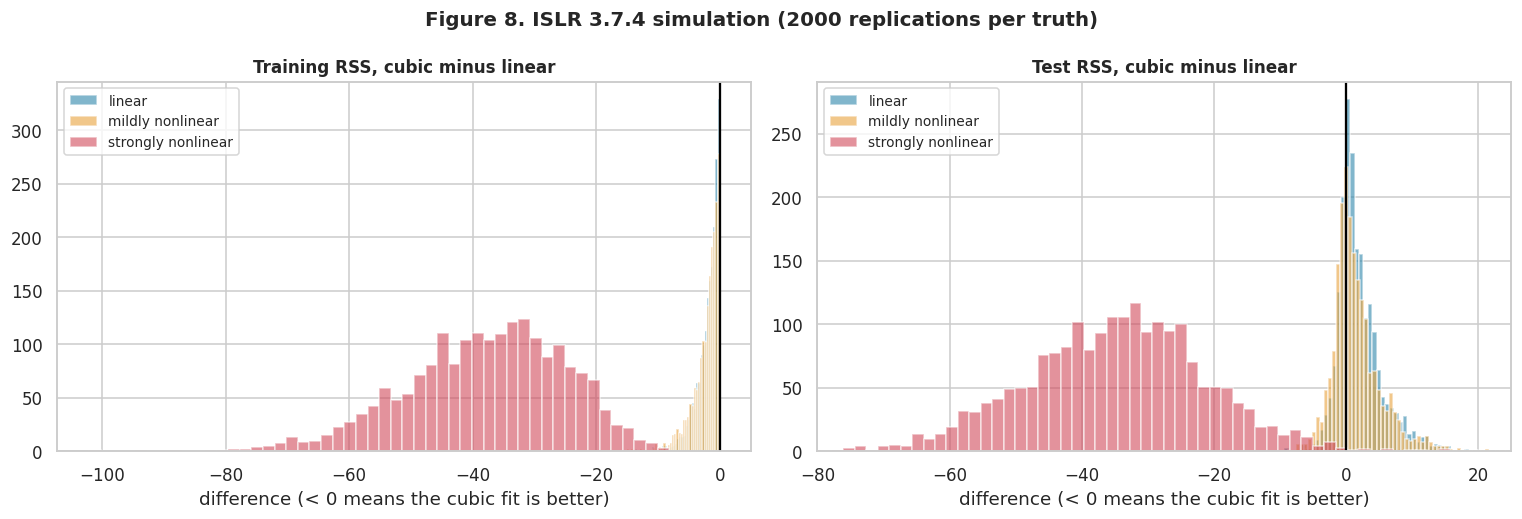

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
colors = ["#2E86AB", "#E8A33D", "#D1495B"]
for (name, d), colr in zip(sims.items(), colors):
    axes[0].hist(d["cubic_train"] - d["linear_train"], bins=50, alpha=0.6, color=colr,
                 label=name.split(":")[0])
    axes[1].hist(d["cubic_test"] - d["linear_test"], bins=60, alpha=0.6, color=colr,
                 label=name.split(":")[0])
for ax, title in zip(axes, ["Training RSS, cubic minus linear",
                            "Test RSS, cubic minus linear"]):
    ax.axvline(0, color="black", lw=1.5)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel("difference (< 0 means the cubic fit is better)")
    ax.legend(fontsize=9)
axes[1].set_xlim(-80, 25)
fig.suptitle("Figure 8. ISLR 3.7.4 simulation (2000 replications per truth)",
             fontsize=13, fontweight="bold")
fig.tight_layout()
plt.show()

2(a). I would expect the cubic regression to have the lower training RSS, or at worst an equal one. Least squares minimises the training RSS over all allowed coefficient values, and the linear model is the special case of the cubic model with $\beta_2 = \beta_3 = 0$, so the cubic fit can always do at least as well on the training data. Even when the true relationship is linear, the two extra terms fit some of the random noise, so in practice the cubic training RSS is strictly lower.

In the simulation with a linear truth, the cubic training RSS is lower in 100% of the replications. The gap is small, about 98 versus 96 on average, because the extra terms only fit noise.

2(b). I would expect the linear regression to have the lower test RSS. When the truth is linear the linear model has no bias, so the extra flexibility of the cubic model cannot reduce bias any further. It only adds variance, because the estimates of $\beta_2$ and $\beta_3$ are fitted to noise that does not recur in new data, and this overfitting makes predictions on new data worse.

This is a statement about expectation. On a particular data set the cubic model can still happen to win. In the simulation the linear test RSS is lower on average and in about three quarters of the replications, but not in all of them.

2(c). I would expect the cubic regression to have the lower training RSS, for the same reason as in 2(a). That argument does not depend on the true relationship. Because the linear model is nested in the cubic model, the cubic least squares fit always has a training RSS at most as large as the linear fit. With a nonlinear truth the cubic model can also capture real curvature, so its advantage on the training data is usually larger. In the simulation the cubic training RSS is lower in 100% of the replications for every true relationship.

2(d). There is not enough information to tell, because the answer depends on how far from linear the true relationship is. If the truth is close to linear, the small reduction in bias from the cubic model can be outweighed by its extra variance, so the linear model may still have the lower test RSS. If the truth is far from linear, the bias of the linear model dominates and the cubic model will have the lower test RSS.

The simulation shows both outcomes. Under the mildly nonlinear truth the linear model still has the lower test RSS on average, while under the strongly nonlinear truth the cubic model wins in nearly every replication. Both relationships are nonlinear, yet the answer reverses, which is why the question cannot be settled without knowing the degree of nonlinearity.

## 3. ISLR 3.7.3 Extra Practice

3.7.3(a). The correct answer is iii. For a fixed value of IQ and GPA, high school graduates earn more on average than college graduates, provided that the GPA is high enough. Holding IQ and GPA fixed, the predicted salary of a college graduate minus that of a high school graduate is $\hat\beta_3 + \hat\beta_5 \cdot \text{GPA} = 35 - 10 \cdot \text{GPA}$, which is negative exactly when the GPA is above 3.5.

3.7.3(b). For a college graduate (Level = 1) with an IQ of 110 and a GPA of 4.0, the predicted starting salary is

$$\hat{y} = 50 + 20(4.0) + 0.07(110) + 35(1) + 0.01(4.0 \times 110) - 10(4.0 \times 1) = 137.1,$$

which is 137.1 thousand dollars, or 137,100 dollars.

3.7.3(c). False. The size of a coefficient alone says nothing about the evidence for an effect. That depends on the coefficient relative to its standard error, through its t statistic or p value, and the standard error is not given. The coefficient is also small partly because of scale. GPA × IQ is a large number, 440 in 3.7.3(b), so the interaction term contributes 0.01 × 440 = 4.4 thousand dollars there, which is not negligible.

In [24]:
# Numerical check of 3.7.3 (b) and the GPA threshold in (a).
b0, b1, b2, b3, b4, b5 = 50, 20, 0.07, 35, 0.01, -10
gpa, iq, level = 4.0, 110, 1
print(f"(b) predicted salary = {b0 + b1*gpa + b2*iq + b3*level + b4*gpa*iq + b5*gpa*level:.1f} thousand")
print(f"(a) college minus high school is negative when GPA > {-b3 / b5:.1f}")

(b) predicted salary = 137.1 thousand
(a) college minus high school is negative when GPA > 3.5


## 3. ISLR 3.7.5 Extra Practice

3.7.5. Writing the fixed index as i and using different letters for the summation indices,

$$\hat{y}_i = x_i \hat\beta = x_i \,\frac{\sum_{i'=1}^{n} x_{i'} y_{i'}}{\sum_{j=1}^{n} x_j^2} = \sum_{i'=1}^{n} \frac{x_i\, x_{i'}}{\sum_{j=1}^{n} x_j^2}\, y_{i'},$$

so

$$a_{i'} = \frac{x_i \, x_{i'}}{\sum_{j=1}^{n} x_j^2}.$$

Each fitted value is therefore a linear combination of the observed responses, with weights that depend only on the x values.

In [25]:
# Numerical check of 3.7.5: the weights reproduce the fitted values exactly.
r = np.random.default_rng(3)
x, y = r.normal(size=8), r.normal(size=8)
beta_hat = (x * y).sum() / (x ** 2).sum()
A = np.outer(x, x) / (x ** 2).sum()           # row i holds a_{i'} for i' = 1..n
print("Largest absolute difference between the two expressions for the fitted values",
      np.abs(x * beta_hat - A @ y).max())

Largest absolute difference between the two expressions for the fitted values 4.440892098500626e-16


## References

1. UCI Machine Learning Repository, Activity Recognition system based on Multisensor data fusion (AReM). https://archive.ics.uci.edu/ml/datasets/Activity+Recognition+system+based+on+Multisensor+data+fusion+%28AReM%29
2. Palumbo, F., Gallicchio, C., Pucci, R., and Micheli, A. (2016). Human activity recognition using multisensor data fusion based on Reservoir Computing. Journal of Ambient Intelligence and Smart Environments, 8(2), pages 87 to 107.
3. Figo, D., Diniz, P. C., Ferreira, D. R., and Cardoso, J. M. P. (2010). Preprocessing techniques for context recognition from accelerometer data. Personal and Ubiquitous Computing, 14(7), pages 645 to 662.
4. Bulling, A., Blanke, U., and Schiele, B. (2014). A tutorial on human activity recognition using body-worn inertial sensors. ACM Computing Surveys, 46(3), Article 33.
5. Christ, M., Braun, N., Neuffer, J., and Kempa-Liehr, A. W. (2018). Time Series FeatuRe Extraction on basis of Scalable Hypothesis tests (tsfresh, a Python package). Neurocomputing, 307, pages 72 to 77.
6. Efron, B., and Tibshirani, R. J. (1993). An Introduction to the Bootstrap. Chapman and Hall/CRC.
7. James, G., Witten, D., Hastie, T., and Tibshirani, R. An Introduction to Statistical Learning, 2nd edition. Chapter 3 (exercises 3.7.3 to 3.7.5) and Section 5.2 on the bootstrap.
8. SciPy documentation for scipy.stats.bootstrap and scipy.stats.f_oneway. https://docs.scipy.org/doc/scipy/reference/stats.html